# Sprint 1 — Análise Exploratória de Dados para Manutenção Preditiva
**Modelagem Linear para Aprendizado de Máquina · Prof. Lucas de Palma · FIAP 1CCPR**
Desafio de Inovação Aberta Motiva Rodovias & FIAP

**Integrantes:** Gustavo Fidelis de Souza e Silva (RM 574666) · Luan Mantovani Ferreira Neres (RM 574563) · Pedro Henrique de Sá (RM 576731) · Fernando Azevedo Costa (RM 575676) · Rafael Meirelles (RM 574897) · Anna Luisa Lima (RM 575081)

**Pergunta:** um sensor instalado no campo, à beira de uma rua, mede o que deveria medir? E quanto o calor e a umidade interferem na leitura? É a mesma dúvida da Motiva com os equipamentos expostos ao tempo nas rodovias (estações meteorológicas, sensores de tráfego, câmeras).

## a) A base de dados
- **Nome:** Air Quality (UCI Machine Learning Repository), doada em 22/03/2016. DOI: 10.24432/C59K5F. Licença CC BY 4.0, uso para pesquisa.
- **Autor:** S. De Vito et al. — *On field calibration of an electronic nose for benzene estimation in an urban pollution monitoring scenario*, Sensors and Actuators B, v. 129, n. 2, 2008.
- **Link:** https://archive.ics.uci.edu/dataset/360/air+quality — consultado em 17/11/2026.
- **O que é:** respostas de um aparelho com 5 sensores químicos de óxido metálico instalado **na rua, ao nível do trânsito**, numa cidade italiana, de março de 2004 a abril de 2005, com uma média por hora. Ao lado, um **analisador de referência certificado** mediu a concentração real dos gases. A própria fonte avisa que os sensores sofrem **deriva** (drift) e interferência de outros gases. Valores ausentes aparecem como −200.
- **Base original:** 9.357 registros por hora e 15 variáveis.

**Como chegamos a 157 registros (procedimento documentado):**
1. Ficamos só com a leitura das **12h** de cada dia (uma por dia): 390 registros.
2. Tiramos os dias em que alguma variável usada estava ausente (−200): ficaram 314.
3. Pegamos **um dia sim, um dia não** (amostra sistemática, começando pelo primeiro): **157 registros**, cobrindo o ano todo (verão e inverno).

As outras colunas da base continuam no arquivo com os valores originais (inclusive −200), para manter a origem; elas não entram na análise.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('base_sensores_air_quality_uci_157.csv')
print(df.shape)
df.head()

(157, 15)


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,11/03/2004,12.00.00,1.6,1236,61,5.2,774,104,1301,95,1401,664,9.5,66.8,0.7951
1,13/03/2004,12.00.00,3.6,1451,210,14.0,1117,239,875,161,1679,1387,18.4,33.8,0.7090
2,15/03/2004,12.00.00,3.1,1430,221,14.1,1120,201,831,134,1783,1522,22.0,34.1,0.8904
3,17/03/2004,12.00.00,2.5,1393,145,12.5,1067,210,905,142,1654,1490,24.3,28.3,0.8471
4,19/03/2004,12.00.00,2.8,1283,-200,14.0,1117,192,813,127,1751,1188,15.5,50.1,0.8744


**Variáveis usadas (todas quantitativas contínuas):**

| Variável | Significado | Unidade |
|---|---|---|
| `PT08.S1(CO)` | resposta do sensor de óxido de estanho voltado ao CO (o "equipamento" que analisamos) | sinal do sensor (sem unidade) |
| `CO(GT)` | concentração real de CO medida pelo analisador de referência | mg/m³ |
| `T` | temperatura do ar | °C |
| `RH` | umidade relativa do ar | % |
| `AH` | umidade absoluta | g/m³ |

In [2]:
vars_ = {'PT08.S1(CO)': 'Resposta do sensor de CO', 'CO(GT)': 'CO real (mg/m³)', 'T': 'Temperatura (°C)', 'RH': 'Umidade relativa (%)', 'AH': 'Umidade absoluta (g/m³)'}
dados = df[list(vars_)].copy()
print('Valores ausentes (-200) nas variáveis usadas:', int((dados == -200).sum().sum()))
print('Linhas duplicadas:', int(df.duplicated().sum()))
dados.dtypes

Valores ausentes (-200) nas variáveis usadas: 0
Linhas duplicadas: 0


PT08.S1(CO)      int64
CO(GT)         float64
T              float64
RH             float64
AH             float64
dtype: object

## b) Média, mediana e moda

In [3]:
def moda_agrupada(s, bins=8):
    # Para variável contínua quase nenhum valor se repete; usamos a moda de Czuber nos dados agrupados
    freq, bordas = np.histogram(s, bins=bins)
    k = freq.argmax(); h = bordas[1] - bordas[0]
    d1 = freq[k] - (freq[k-1] if k > 0 else 0); d2 = freq[k] - (freq[k+1] if k < len(freq)-1 else 0)
    return bordas[k] + h * d1 / (d1 + d2) if (d1 + d2) else (bordas[k] + bordas[k+1]) / 2

tab = pd.DataFrame({
    'média': dados.mean(), 'mediana': dados.median(),
    'moda (valor mais repetido)': dados.mode().iloc[0],
    'vezes que repete': [int((dados[c] == dados.mode().iloc[0][c]).sum()) for c in dados],
    'moda agrupada (Czuber)': [moda_agrupada(dados[c]) for c in dados]
}).round(2)
tab.index = [vars_[c] for c in tab.index]
tab

,média,mediana,moda (valor mais repetido),vezes que repete,moda agrupada (Czuber)
Resposta do sensor de CO,1121.04,1103.0,959.00,4,1095.08
CO real (mg/m³),2.12,2.0,1.40,15,1.67
Temperatura (°C),21.25,20.9,11.80,4,15.14
Umidade relativa (%),38.88,34.8,23.50,3,27.57
Umidade absoluta (g/m³),0.96,0.9,0.82,2,0.87


**Interpretação:**
- O **sensor** marca em média **1.121** e a mediana é **1.103**: média um pouco acima da mediana, sinal de alguns dias com leitura bem alta puxando a média para cima.
- O **CO real** fica em média em **2,12 mg/m³** (mediana 2,0): a maior parte do tempo é poluição moderada, com picos de até 4,9.
- A **temperatura** vai de 3,7 °C a 40,3 °C, com média de 21,3 °C: o sensor trabalhou no frio e no calor, como um equipamento de rodovia.
- A **umidade relativa** tem média 38,9% e mediana 34,8%: a média maior que a mediana mostra dias muito úmidos (até 86,5%) puxando para cima.
- Nas variáveis contínuas quase nenhum valor se repete (o "valor mais repetido" do sensor aparece só 4 vezes), então a **moda agrupada** (classe mais frequente do histograma) descreve melhor o valor típico: cerca de **1.095** no sensor. O CO real é medido com uma casa decimal, por isso o valor 1,4 mg/m³ se repete 15 vezes e é a moda; a moda agrupada fica em 1,67.

## c) Separatrizes: quartis, decis e percentis

In [4]:
sep = dados.quantile([0.10, 0.25, 0.50, 0.75, 0.90, 0.95]).T.round(2)
sep.columns = ['D1 (P10)', 'Q1 (P25)', 'Q2 (P50)', 'Q3 (P75)', 'D9 (P90)', 'P95']
sep['amplitude interquartil (Q3-Q1)'] = (sep['Q3 (P75)'] - sep['Q1 (P25)']).round(2)
sep.index = [vars_[c] for c in sep.index]
sep

,D1 (P10),Q1 (P25),Q2 (P50),Q3 (P75),D9 (P90),P95,amplitude interquartil (Q3-Q1)
Resposta do sensor de CO,895.80,973.00,1103.0,1236.00,1392.40,1448.60,263.0
CO real (mg/m³),1.00,1.40,2.0,2.70,3.40,3.92,1.3
Temperatura (°C),9.16,13.40,20.9,28.50,34.74,37.24,15.1
Umidade relativa (%),20.56,26.20,34.8,52.40,61.86,66.84,26.2
Umidade absoluta (g/m³),0.44,0.66,0.9,1.16,1.55,1.69,0.5


Usamos **quartis** (Q1, Q2, Q3), os **decis** D1 e D9 e o **percentil 95**.

**Interpretação:**
- Metade dos dias o sensor ficou entre **973 e 1.236** (Q1 a Q3). Uma leitura acima de **1.392** (D9) já está entre os 10% mais altos do ano e pode servir de primeiro limite de alerta.
- O CO real ficou entre **1,4 e 2,7 mg/m³** em metade dos dias; só 10% dos dias passaram de 3,5 mg/m³.
- A temperatura tem amplitude interquartil de **15 °C** (13,4 a 28,5 °C): o equipamento enfrenta estações muito diferentes, e isso importa para a manutenção (o sensor precisa ser conferido nas duas estações).
- Em manutenção, os percentis ajudam a definir **faixas normais** de operação: o que fica entre P10 e P90 é o comportamento comum; o que passa disso merece inspeção.

## d) Histogramas: distribuição e dispersão

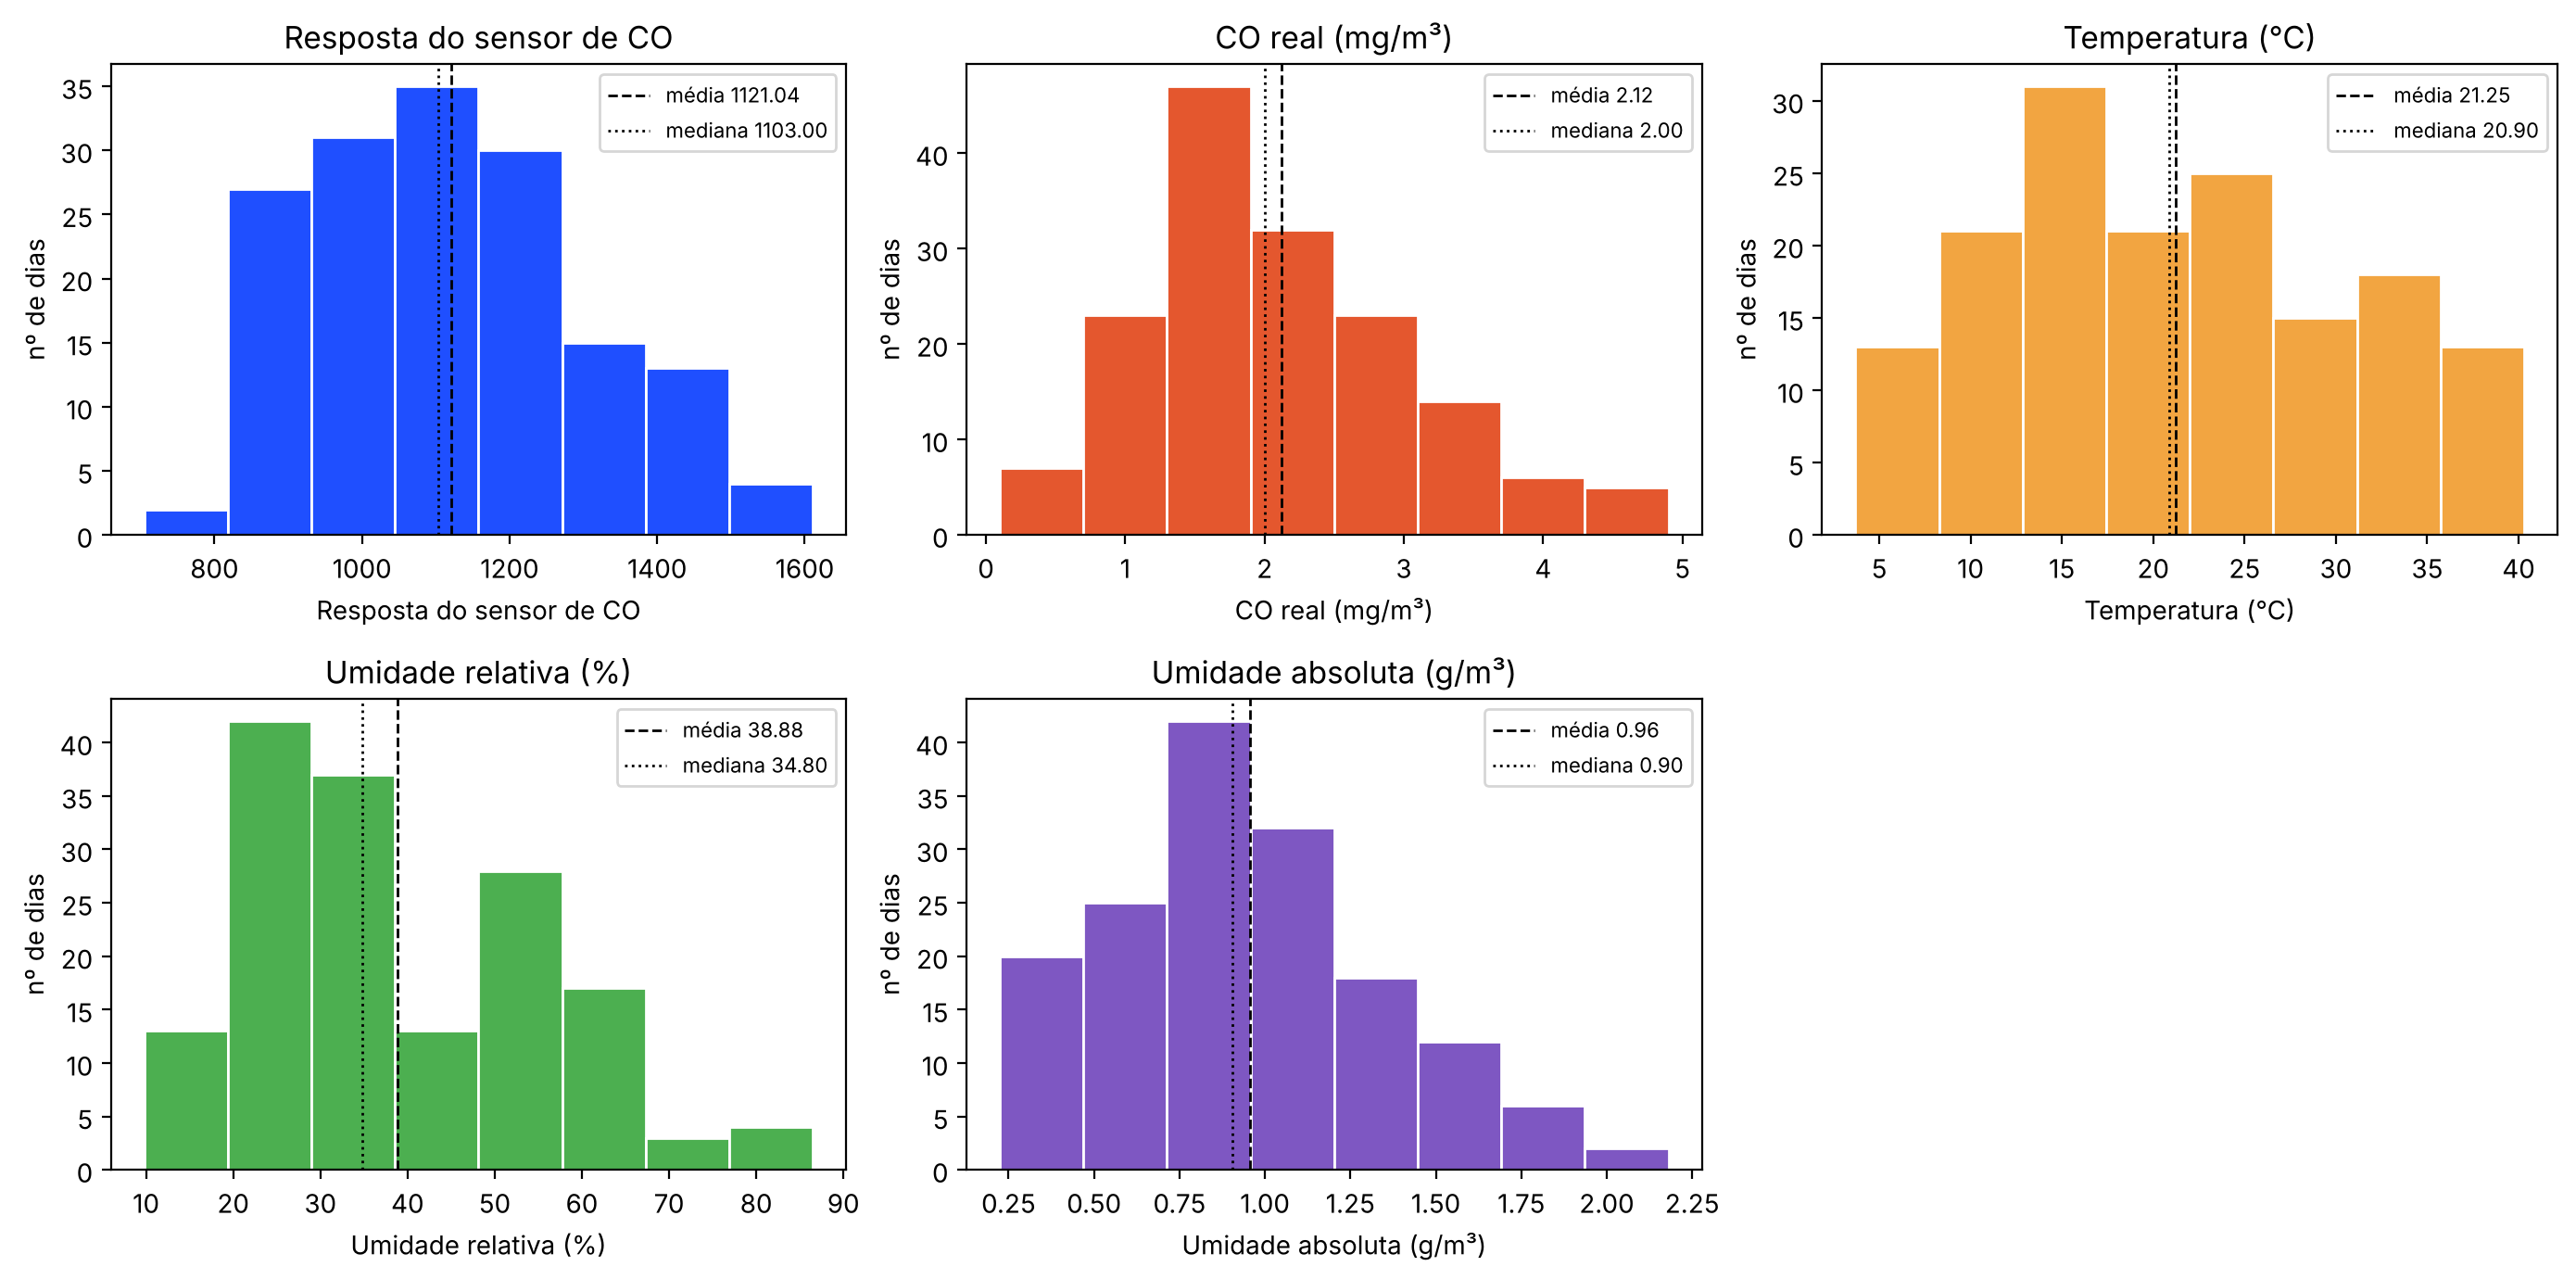

,desvio padrão,coef. de variação (%),assimetria
Resposta do sensor de CO,186.55,16.64,0.37
CO real (mg/m³),0.97,45.68,0.56
Temperatura (°C),9.52,44.81,0.18
Umidade relativa (%),16.55,42.56,0.58
Umidade absoluta (g/m³),0.40,42.23,0.56


In [5]:
fig, axs = plt.subplots(2, 3, figsize=(14, 7))
cores = ['#1F4FFF', '#E4572E', '#F2A541', '#4CAF50', '#7E57C2']
for ax, (c, nome), cor in zip(axs.flat, vars_.items(), cores):
    ax.hist(dados[c], bins=8, color=cor, edgecolor='white')
    ax.axvline(dados[c].mean(), color='black', ls='--', lw=1, label=f'média {dados[c].mean():.2f}')
    ax.axvline(dados[c].median(), color='black', ls=':', lw=1, label=f'mediana {dados[c].median():.2f}')
    ax.set_title(nome); ax.set_xlabel(nome); ax.set_ylabel('nº de dias'); ax.legend(fontsize=8)
axs.flat[-1].axis('off')
plt.tight_layout(); plt.savefig('histogramas.png', dpi=150); plt.show()

disp = pd.DataFrame({'desvio padrão': dados.std(), 'coef. de variação (%)': dados.std() / dados.mean() * 100,
                     'assimetria': dados.skew()}).round(2)
disp.index = [vars_[c] for c in disp.index]
disp

**Interpretação:**
- **Sensor de CO:** distribuição quase simétrica com leve cauda à direita (assimetria positiva). Coeficiente de variação de **cerca de 17%**: variação moderada.
- **CO real:** cauda à direita mais clara; CV de **cerca de 46%**, o gás real varia muito mais que a leitura do sensor. Isso já indica que o sensor "achata" os extremos.
- **Temperatura:** distribuição larga e espalhada, sem um pico forte, porque junta dias de inverno e de verão.
- **Umidade relativa:** dois grupos, ou seja, distribuição bimodal: muitos dias secos entre 20% e 40% (verão) e outro grupo entre 50% e 60% (outono e inverno), com poucos dias acima de 70%.
- **Umidade absoluta:** cauda à direita, com os maiores valores no verão (ar quente segura mais água).

## Gráficos de dispersão e correlação

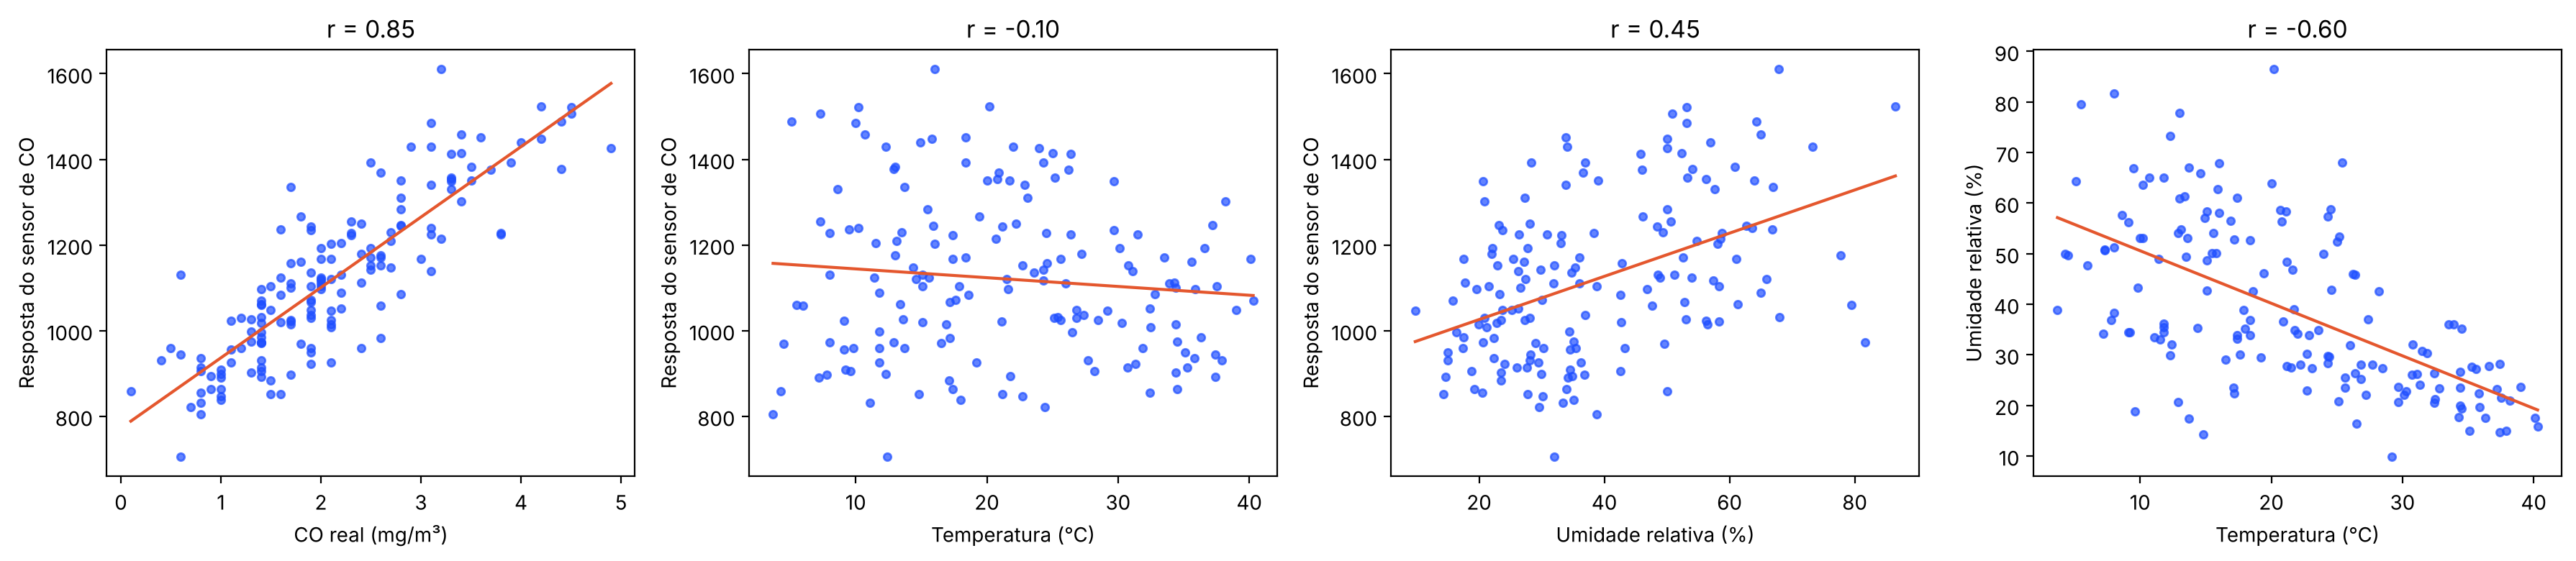

,Resposta do sensor de CO,CO real (mg/m³),Temperatura (°C),Umidade relativa (%),Umidade absoluta (g/m³)
Resposta do sensor de CO,1.00,0.85,-0.10,0.45,0.24
CO real (mg/m³),0.85,1.00,-0.11,0.32,0.14
Temperatura (°C),-0.10,-0.11,1.00,-0.60,0.64
Umidade relativa (%),0.45,0.32,-0.60,1.00,0.18
Umidade absoluta (g/m³),0.24,0.14,0.64,0.18,1.00


In [6]:
pares = [('CO(GT)', 'PT08.S1(CO)'), ('T', 'PT08.S1(CO)'), ('RH', 'PT08.S1(CO)'), ('T', 'RH')]
fig, axs = plt.subplots(1, 4, figsize=(18, 4))
for ax, (x, y) in zip(axs, pares):
    r = dados[x].corr(dados[y])
    a, b = np.polyfit(dados[x], dados[y], 1)
    ax.scatter(dados[x], dados[y], s=14, alpha=.7, color='#1F4FFF')
    xs = np.linspace(dados[x].min(), dados[x].max(), 50); ax.plot(xs, a * xs + b, color='#E4572E')
    ax.set_xlabel(vars_[x]); ax.set_ylabel(vars_[y]); ax.set_title(f'r = {r:.2f}')
plt.tight_layout(); plt.savefig('dispersao.png', dpi=150); plt.show()

corr = dados.corr().round(2)
corr.index = corr.columns = [vars_[c] for c in corr.columns]
corr

**Interpretação:**
- **Sensor × CO real: correlação forte e positiva (r ≈ 0,85).** O sensor acompanha o gás real: quando o CO sobe, a leitura sobe. Ele funciona, mas não é perfeito: cerca de 28% da variação da leitura (1 − r²) não é explicada pelo gás.
- **Sensor × temperatura: correlação muito fraca e negativa (r ≈ −0,10).** Sozinha, a temperatura quase não acompanha a leitura.
- **Sensor × umidade relativa: correlação moderada e positiva (r ≈ 0,45).** É o achado mais importante: a leitura do sensor acompanha a umidade **mais** do que o próprio CO real acompanha a umidade (r ≈ 0,32). Isso sugere que a umidade "empurra" a leitura do sensor para cima além do que o gás explica, exatamente o tipo de interferência do ambiente que a fonte descreve.
- **Temperatura × umidade relativa: correlação negativa forte (r ≈ −0,60)**: dias quentes são mais secos.
- **Correlação não é causa.** Temperatura, umidade e poluição mudam juntas ao longo do ano, e isso se mistura. Para separar o efeito do tempo do efeito do gás, o próximo passo é um modelo linear com várias variáveis (Sprint 2).

## Conclusões para a manutenção (ligação com a Motiva)
1. Um sensor de baixo custo no campo **acompanha bem** a medida de referência (r ≈ 0,87), mas com erro que muda ao longo do ano.
2. A **umidade** aparece junto com a leitura (r ≈ 0,45) mais do que com o gás real. É o mesmo problema das câmeras e sensores da rodovia: parte do "defeito" pode ser condição do tempo.
3. Os **percentis** dão faixas de operação normal (P10 a P90) que podem virar regras de alerta.
4. Próximo passo: regressão linear da leitura do sensor contra CO real, temperatura e umidade, para medir quanto de cada um pesa e detectar **deriva** do sensor (quando o erro cresce com o tempo, é hora de calibrar ou trocar).

*Uso de IA:* o Claude (Anthropic) ajudou a escolher a base, escrever o código e as interpretações; o Gustavo Fidelis revisou.